In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import nibabel as nib
import numpy as np
import pandas as pd
from nilearn import plotting
from nilearn.image import resample_to_img
from nilearn.maskers import NiftiMasker
from scipy.spatial.distance import pdist, squareform
from scipy.stats import spearmanr

if not hasattr(np, "row_stack"):  # brainsmash 0.11 usa un alias que NumPy 2.5 ya quito
    np.row_stack = np.vstack

from brainsmash.mapgen.base import Base

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
RAW, PROC, FIG = ROOT / "data" / "raw", ROOT / "data" / "processed", ROOT / "figures"
PROC.mkdir(parents=True, exist_ok=True)
FIG.mkdir(exist_ok=True)
sys.path.insert(0, str(ROOT / "src"))
import estilo as E

E.aplicar_estilo()

pd.set_option("display.width", 140)

GENES = {
    "CNR1": ("CB1", "receptor"),
    "CNR2": ("CB2", "receptor"),
    "DAGLA": ("DAGLα", "fabrica 2-AG"),
    "DAGLB": ("DAGLβ", "fabrica 2-AG"),
    "MGLL": ("MAGL", "degrada 2-AG"),
    "ABHD6": ("ABHD6", "degrada 2-AG"),
    "ABHD12": ("ABHD12", "degrada 2-AG"),
    "NAPEPLD": ("NAPE-PLD", "fabrica anandamida"),
    "FAAH": ("FAAH", "degrada anandamida"),
}





In [2]:
# Celda 2 Las regiones del atlas y su centro en milimetros
atlas = nib.load(RAW / "atlas-desikankilliany.nii.gz")
regiones = pd.read_csv(RAW / "atlas-desikankilliany.csv").set_index("id")

SUB = { # nombre en el atlas: (nombre en ENIGMA, nombre en español)
    "thalamusproper": ("thal", "talamo"),
    "caudate": ("caud", "caudado"),
    "putamen": ("put", "putamen"),
    "pallidum": ("pal", "palido"),
    "accumbensarea": ("accumb", "accubens"),
    "hippocampus": ("hippo", "hipocampo"),
    "amygdala": ("amyg", "amigdala")
}

def nombres(r):
    if r.structure == "cortex":
        return f"{r.hemisphere}_{r.label}", r.label
    if r.label in SUB:
        return f"{r.hemisphere}{SUB[r.label][0]}", SUB[r.label][1]
    return None, r.label

regiones[["enigma", "nombre"]] = regiones.apply(nombres, axis=1, result_type="expand")
regiones["tejido"] = np.where(regiones.structure == "cortex", "corteza", "subcortical")

voxeles = np.asarray(atlas.dataobj)

centros = { i: nib.affines.apply_affine(atlas.affine, np.argwhere(voxeles == i).mean(axis=0))
    for i in regiones.index}
regiones[["x", "y", "z"]] = pd.DataFrame(centros, index=["x", "y", "z"]).T
print(regiones.groupby(["hemisphere", "tejido"]).size())

hemisphere  tejido     
B           subcortical     1
L           corteza        34
            subcortical     7
R           corteza        34
            subcortical     7
dtype: int64


In [3]:
# Celda 3 Promedio de cada mapa PET dentro de cada region

from nilearn.maskers import NiftiLabelsMasker

def parcelar(archivo):
    pet = resample_to_img(RAW / archivo, atlas, interpolation="continuous", force_resample=True, copy_header=True)
    masker = NiftiLabelsMasker(labels_img=atlas, strategy="mean", standardize=None)
    valores = masker.fit_transform(pet).ravel()
    ids = [int(v) for k, v in masker.region_ids_.items() if k != "background"]
    return pd.Series(valores, index=ids)

regiones["CB1_omar"] = parcelar("CB1_omar_hc77_normandin.nii.gz")
regiones["CB1_fmpep"] = parcelar("CB1_FMPEPd2_hc22_laurikainen.nii")
regiones[["CB1_omar", "CB1_fmpep"]].describe().round(2)

,CB1_omar,CB1_fmpep
count,83.00,83.00
mean,1.30,8.28
std,0.12,1.50
min,0.91,3.26
25%,1.25,7.57
50%,1.32,8.63
75%,1.38,9.44
max,1.63,10.87


In [4]:
# Celda 4 La expresion de los 9 genes; nos quedamos con el hemisferio izquierdo
ahba = pd.read_csv(RAW / "allgenes_stable_r-1.csv", usecols=["label", *GENES]).set_index("label")
tabla = regiones.join(ahba, on="enigma")
izq = tabla[tabla.hemisphere == "L"].copy()
ctx = izq[izq.tejido == "corteza"]
print(izq.shape[0], "regiones:", (izq.tejido == "corteza").sum(), "de corteza y", (izq.tejido == "subcortical").sum(), "subcorticales")
print("Valores faltantes:", int(izq[list(GENES)].isna().sum().sum()))

41 regiones: 34 de corteza y 7 subcorticales
Valores faltantes: 0


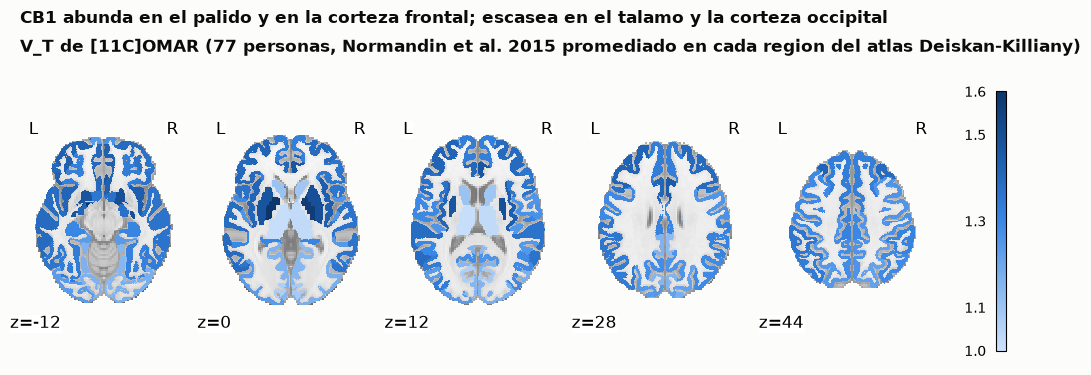

In [5]:
# Celda 5 Figura 1: El mapa de CB1 por region (los dos hemisferios)

mapa = np.zeros(voxeles.shape, dtype="float32")
for i, v in regiones.CB1_omar.items():
    mapa[voxeles == i] = v
img = nib.Nifti1Image(mapa, atlas.affine)

fig = plt.figure(figsize=(10, 3.6))
plotting.plot_stat_map(
    img, display_mode="z", cut_coords=[-12, 0, 12, 28, 44], cmap=E.SECUENCIAL, vmin=1.0, vmax=1.6, symmetric_cbar=False, threshold=0.01, black_bg=False, draw_cross=False, annotate=True, colorbar=True, cbar_tick_format="%.1f", figure=fig, axes=(0, 0, 1, 0.8),
)
fig.text(0.01, 0.95, "CB1 abunda en el palido y en la corteza frontal; escasea en el talamo y la corteza occipital", fontsize=12, fontweight="bold", color=E.TINTA)
fig.text(0.01, 0.87, "V_T de [11C]OMAR (77 personas, Normandin et al. 2015 promediado en cada region del atlas Deiskan-Killiany)", fontsize=12, fontweight="bold", color=E.TINTA)
fig.savefig(FIG / "fig1_mapa_cb1.png")
plt.show()

In [6]:
# Celda 6 Los dos trazadores cuentan la misma historia?
for nombre, df in [("41 regiones", izq), ("corteza(34)", ctx)]:
    r, p = spearmanr(df.CB1_omar, df.CB1_fmpep)
    print(f"OMAR vs FMPEP-d2, {nombre}: rho = {r:.2f}, p{p:.3g}")

OMAR vs FMPEP-d2, 41 regiones: rho = 0.49, p0.00112
OMAR vs FMPEP-d2, corteza(34): rho = 0.46, p0.00589


In [7]:
# Celda 7 p-valor contra mapas nulos que conversala autocorrelacion espacial
def p_espacial(x, y, coords, n=1000, semilla=42):
    """Spearman entre x e y, y su p de dos colas contra n mapas nulos hechos a partir de x."""
    D= squareform(pdist(coords))
    nulos = Base(x=np.asarray(x), D=D, seed=semilla)(n=n)
    r = spearmanr(x, y).statistic
    r_nulos = np.array([spearmanr(s, y).statistic for s in nulos])
    return r, (1 + np.sum(np.abs(r_nulos) >= abs(r))) / (1 + n)

resultados = []
for trazador in ["CB1_omar", "CB1_fmpep"]:
    for nombre, df in [("corteza", ctx), ("41 regiones", izq)]:
        r, p = p_espacial(df[trazador], df.CNR1, df[["x", "y", "z"]].values)
        resultados.append({"PET": trazador, "regiones": nombre, "rho": round(r, 2), "p_espacial": round(p, 3)})
pd.DataFrame(resultados)

,PET,regiones,rho,p_espacial
0,CB1_omar,corteza,0.72,0.005
1,CB1_omar,41 regiones,0.54,0.076
2,CB1_fmpep,corteza,0.10,0.826
3,CB1_fmpep,41 regiones,-0.01,0.983


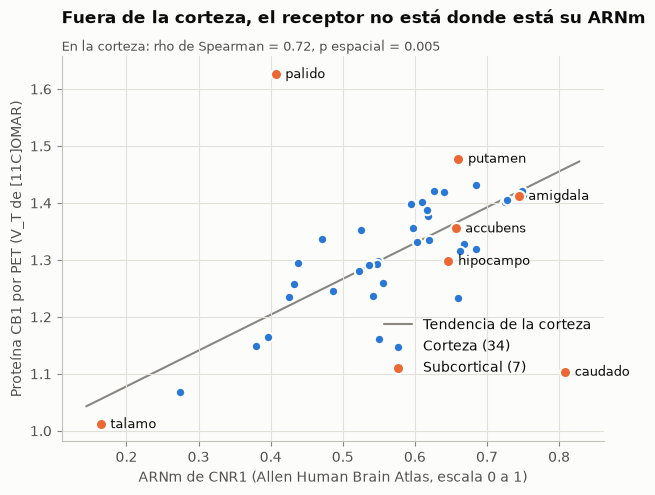

In [8]:
# Celda 8 · Figura 2: ARNm de CNR1 contra proteína CB1
b, a = np.polyfit(ctx.CNR1, ctx.CB1_omar, 1)  # la regla aprendida en la corteza
sub = izq[izq.tejido == "subcortical"]

fig, ax = plt.subplots(figsize=(7, 5))
ax.grid(True, zorder=0)
xs = np.linspace(izq.CNR1.min() - 0.02, izq.CNR1.max() + 0.02, 50)
ax.plot(xs, a + b * xs, color=E.GRIS, lw=1.5, zorder=1, label="Tendencia de la corteza")
ax.scatter(ctx.CNR1, ctx.CB1_omar, s=46, color=E.AZUL, edgecolor=E.FONDO, linewidth=1.5, zorder=3, label="Corteza (34)")
ax.scatter(sub.CNR1, sub.CB1_omar, s=64, color=E.NARANJA, edgecolor=E.FONDO, linewidth=1.5, zorder=3, label="Subcortical (7)")
for _, r in sub.iterrows():
    ax.annotate(r.nombre, (r.CNR1, r.CB1_omar), xytext=(7, -3), textcoords="offset points", fontsize=9, color=E.TINTA)
ax.set_xlabel("ARNm de CNR1 (Allen Human Brain Atlas, escala 0 a 1)")
ax.set_ylabel("Proteína CB1 por PET (V_T de [11C]OMAR)")
fila = pd.DataFrame(resultados).query("PET == 'CB1_omar' and regiones == 'corteza'").iloc[0]
ax.set_title("Fuera de la corteza, el receptor no está donde está su ARNm", pad=24)
ax.text(0, 1.015, f"En la corteza: rho de Spearman = {fila.rho:.2f}, p espacial = {fila.p_espacial:.3f}",
        transform=ax.transAxes, fontsize=9.5, color=E.TINTA_2)
ax.legend(loc="lower right", bbox_to_anchor=(1, 0.14))
fig.savefig(FIG / "fig2_arnm_vs_proteina.png")
plt.show()

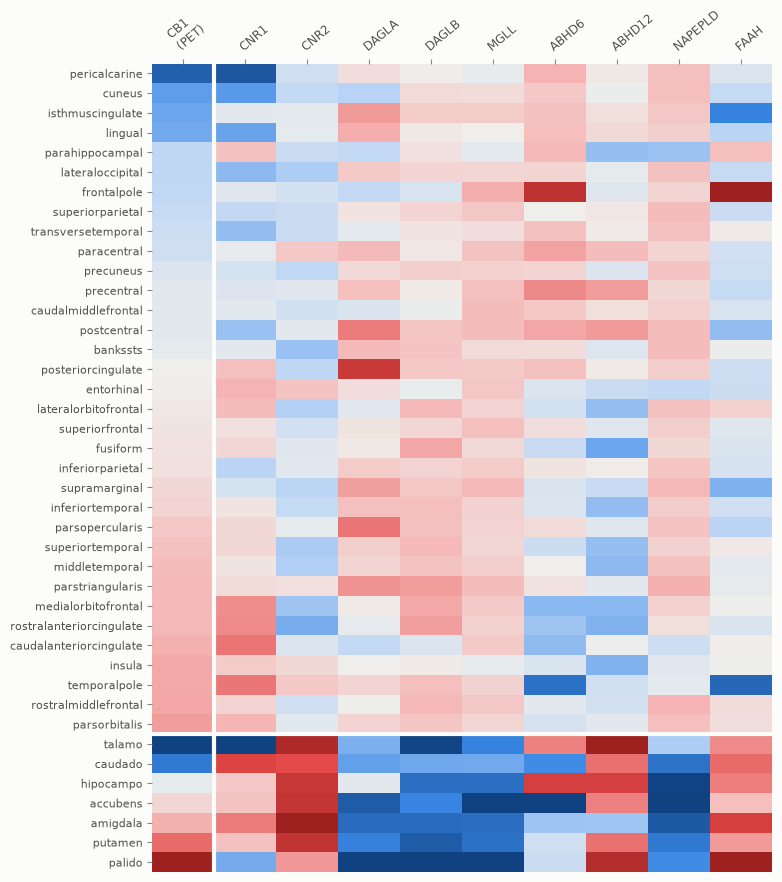

In [10]:
# Celda 9 Figura 3: los 9 genes y el PET en las 41 regiones (z-scores)
orden = pd.concat([ctx.sort_values("CB1_omar"), sub.sort_values("CB1_omar")])
columnas = ["CB1_omar", *GENES]
z = (orden[columnas] - izq[columnas].mean()) / izq[columnas].std()
z.index = orden.nombre
z.columns = ["CB1\n(PET)", *GENES]

fig, ax = plt.subplots(figsize=(8, 10.5))
lim = 2.5
im = ax.imshow(z.values, cmap=E.DIVERGENTE, vmin=-lim, vmax=lim, aspect="auto")
ax.set_xticks(range(z.shape[1]), z.columns, fontsize=8.5, rotation=40, ha="left", rotation_mode="anchor")
ax.set_yticks(range(z.shape[0]), z.index, fontsize=8)
ax.xaxis.tick_top()
ax.axhline(len(ctx) - 0.5, color=E.FONDO, lw=3)
ax.axvline(0.5, color=E.FONDO, lw=3)
for s in ax.spines.values():
    s.set_visible(False)

In [11]:
# Celda 10 Que genes varian juntos dentro de la corteza?

ctx[list(GENES)].corr(method="spearman").round(2)

,CNR1,CNR2,DAGLA,DAGLB,MGLL,ABHD6,ABHD12,NAPEPLD,FAAH
CNR1,1.00,0.07,-0.19,0.35,0.04,-0.66,-0.56,-0.49,0.35
CNR2,0.07,1.00,0.22,-0.32,0.17,0.18,0.35,-0.23,-0.28
DAGLA,-0.19,0.22,1.00,0.28,0.17,0.22,0.30,0.33,-0.57
DAGLB,0.35,-0.32,0.28,1.00,-0.01,-0.53,-0.51,0.32,0.04
MGLL,0.04,0.17,0.17,-0.01,1.00,0.10,0.26,0.11,-0.15
ABHD6,-0.66,0.18,0.22,-0.53,0.10,1.00,0.70,0.14,-0.20
ABHD12,-0.56,0.35,0.30,-0.51,0.26,0.70,1.00,0.25,-0.38
NAPEPLD,-0.49,-0.23,0.33,0.32,0.11,0.14,0.25,1.00,-0.09
FAAH,0.35,-0.28,-0.57,0.04,-0.15,-0.20,-0.38,-0.09,1.00


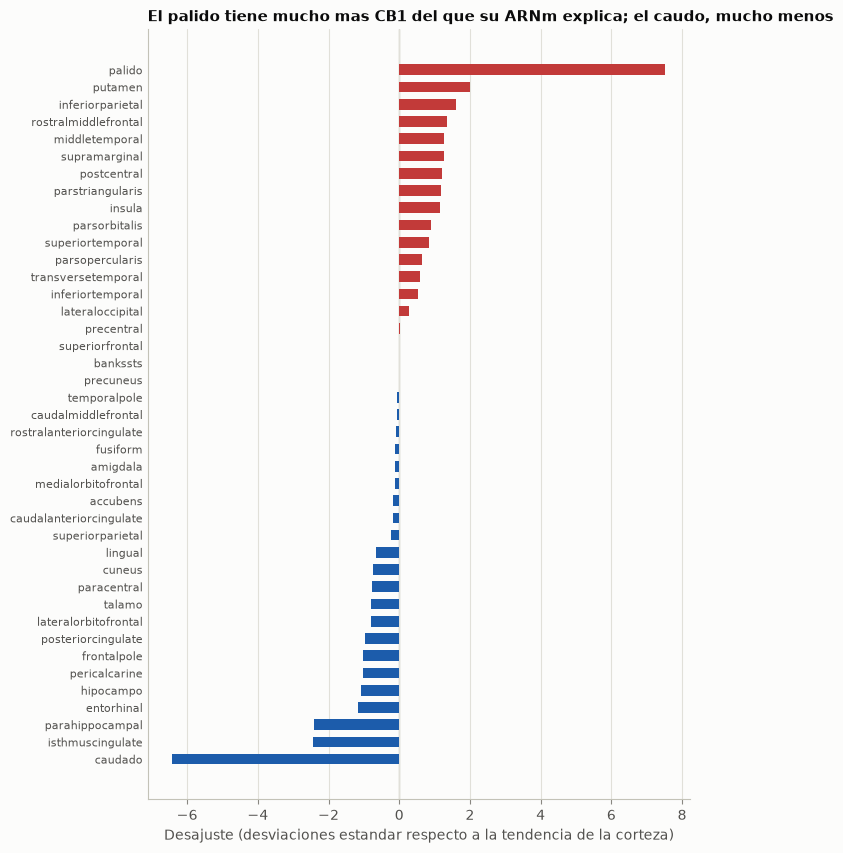

,nombre,tejido,CB1_omar,CNR1,desajuste
id,,,,,
36,caudado,subcortical,1.10,0.81,-6.42
9,isthmuscingulate,corteza,1.16,0.55,-2.45
15,parahippocampal,corteza,1.23,0.66,-2.40
7,inferiorparietal,corteza,1.34,0.47,1.60
37,putamen,subcortical,1.48,0.66,1.99
38,palido,subcortical,1.63,0.41,7.53


In [14]:
# Celda 11 Figura 4: cuanto CB1 sobra o falta respecto a su ARNm
residuo = izq.CB1_omar - (a + b * izq.CNR1)
izq["desajuste"] = residuo / (ctx.CB1_omar - (a + b * ctx.CNR1)).std()
d = izq.sort_values("desajuste")

fig, ax = plt.subplots(figsize=(7,10))
colores = np.where(d.desajuste > 0, E.ROJO_OSCURO, E.AZUL_OSCURO)
ax.barh(range(len(d)), d.desajuste, height=0.62, color=colores, zorder=2)
ax.set_yticks(range(len(d)), d.nombre, fontsize=8)
ax.axvline(0, color=E.EJE, lw=1, zorder=1)
ax.grid(True, axis="x", zorder=0)
ax.set_xlabel("Desajuste (desviaciones estandar respecto a la tendencia de la corteza)")
ax.set_title("El palido tiene mucho mas CB1 del que su ARNm explica; el caudo, mucho menos", fontsize=11)
ax.tick_params(axis="y",length=0)
fig.savefig(FIG / "fig4_desajustes.png")
plt.show()
d[["nombre", "tejido", "CB1_omar", "CNR1", "desajuste"]].round(2).iloc[[0, 1, 2, -3, -2, -1]]

In [16]:
# Celda 12 Balance entre fabricar y degradar, por ligando

zg =  (izq[list(GENES)] - izq[list(GENES)].mean()) / izq[list(GENES)].std()
izq["balance_2AG"] =  zg.DAGLA - zg.MGLL
izq["balance_AEA"] = zg.NAPEPLD - zg.FAAH
for col in ["balance_2AG", "balance_AEA"]:
    o = izq.sort_values(col)
    print(col, "| mas bajo:", ", ".join(o.nombre.head(3)), "| mas alto:", ", ". join(o.nombre.tail(3)))

balance_2AG | mas bajo: frontalpole, caudalanteriorcingulate, cuneus | mas alto: parsopercularis, posteriorcingulate, hipocampo
balance_AEA | mas bajo: palido, amigdala, hipocampo | mas alto: temporalpole, supramarginal, isthmuscingulate


In [17]:
# Celda 13 Guardar la tabla para los notebooks 02 y 03
columnas = ["label", "nombre", "tejido", "x", "y", "z", "CB1_omar", "CB1_fmpep", *GENES, "desajuste", "balance_2AG", "balance_AEA"]
izq[columnas].to_csv(PROC / "regiones_izq.csv")
print("Guardado:", (PROC / "regiones_izq.csv").relative_to(ROOT), izq[columnas].shape)

Guardado: data/processed/regiones_izq.csv (41, 20)
